# MSDS 451 — Term Project Checkpoint C
## Machine Learning–Enhanced Adaptive Momentum ETF: Performance Evaluation

This notebook evaluates the momentum ETF strategy from Checkpoints A and B using the PA3 backtest. I compare it with SPY, calculate alpha and beta, and test results across market conditions and simulated returns.

I keep the original trading rule for this checkpoint. Machine learning is not included yet.


### 1. Setup and ETF data

I use the six Yahoo Finance CSV files downloaded for Checkpoint B on October 26, 2026. SPY, XLF, XLV, IEF, and GLD are the investment candidates, while SHY is the fallback. I use Adjusted Close to calculate returns, although it is not an actual trading price.

The original files are in `data/raw/`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TICKERS = ['SPY', 'XLF', 'XLV', 'IEF', 'GLD', 'SHY']
CANDIDATES = TICKERS[:-1]
BASE_LOOKBACK = 126
SMA_DAYS = 200
BASE_TRADING_BPS = 10.0
BASE_MANAGEMENT_FEE = 0.0025
SEED = 4512026
# Monte Carlo settings
N_LONG_PATHS = 160
N_WALK_FORWARD_PER_YEAR = 24
MEAN_BOOTSTRAP_BLOCK_DAYS = 21

def find_project_root():
    here = Path.cwd().resolve()
    candidates = [here, here.parent, here.parent.parent]
    candidates += [p / 'Checkpoint_C' for p in candidates]
    for base in (here, here.parent):
        if base.is_dir():
            candidates.extend(p for p in base.iterdir() if p.is_dir() and 'Checkpoint_C' in p.name)
    for folder in candidates:
        if all((folder / 'data' / 'raw' / f'{t}_daily_history.csv').is_file() for t in TICKERS):
            return folder
    raise FileNotFoundError('The six ETF CSVs are missing. Extract the complete Checkpoint_C folder, including data/raw/.')

ROOT = find_project_root()
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
for folder in (PROCESSED, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
print('ETF CSV files found:', len(list(RAW.glob('*_daily_history.csv'))))

ETF CSV files found: 6


In [2]:
series = {}
for t in TICKERS:
    frame = pd.read_csv(RAW / f'{t}_daily_history.csv', parse_dates=['Date']).set_index('Date').sort_index()
    assert frame.index.is_unique and frame['Adj Close'].notna().all()
    assert (frame['Adj Close'] > 0).all()
    series[t] = frame['Adj Close'].astype(float).rename(t)
prices = pd.concat(series.values(), axis=1).dropna().sort_index()
daily_returns = prices.pct_change().iloc[1:]
assert len(prices) == 5518 and len(daily_returns) == 5517
assert prices.index.min() == pd.Timestamp('2004-11-18')
assert prices.index.max() == pd.Timestamp('2026-10-26')
prices.to_csv(PROCESSED / 'adjusted_prices_aligned.csv', index_label='Date', float_format='%.10f')
print('Common adjusted-price period:', prices.index.min().date(), 'to', prices.index.max().date())
print('Observations:', len(prices), '| daily returns:', len(daily_returns))

Common adjusted-price period: 2004-11-18 to 2026-10-26
Observations: 5518 | daily returns: 5517


### 2. Trading rules and backtest

I use the same rules as PA3. At each completed month-end, I check 126-day momentum and the 200-day moving average. The two highest-ranked eligible ETFs get 50% each, and any remaining weight goes to SHY. Trades are made at the next trading-day close, so the new holdings do not earn that day's earlier return.

The base case includes 10 basis points per dollar traded and a 0.25% annual management fee.


In [3]:
def month_end_positions(index):
    periods = index.to_period('M')
    return np.where(np.r_[periods[:-1] != periods[1:], True])[0]

def build_trade_targets(price_frame, lookback=BASE_LOOKBACK):
    p = price_frame.to_numpy(dtype=float)
    ix = price_frame.index
    out = {}
    signals = []
    for k in month_end_positions(ix):
        if k < max(SMA_DAYS - 1, lookback) or k + 1 >= len(ix):
            continue
        # Skip the last month if there is no next trading day.
        momentum = p[k] / p[k - lookback] - 1
        sma = p[k - SMA_DAYS + 1:k + 1].mean(axis=0)
        eligible = [j for j in range(5) if momentum[j] > 0 and p[k, j] > sma[j]]
        selected = sorted(eligible, key=lambda j: (-momentum[j], TICKERS[j]))[:2]
        target = np.zeros(len(TICKERS), dtype=float)
        for j in selected:
            target[j] = 0.5
        target[5] = 1.0 - target.sum()
        out[k+1] = target
        signals.append({'SignalDate':ix[k], 'TradeDate':ix[k+1],
                        'Selected1':TICKERS[selected[0]] if selected else '',
                        'Selected2':TICKERS[selected[1]] if len(selected)>1 else '',
                        **{f'TargetWeight_{t}':target[j] for j,t in enumerate(TICKERS)}})
    return out, pd.DataFrame(signals)

def gross_stream(price_frame, trade_map, evaluation_start):
    p = price_frame.to_numpy(dtype=float)
    dates = price_frame.index
    first = int(dates.searchsorted(pd.Timestamp(evaluation_start)))
    assert first in trade_map, 'Evaluation should start at the first scheduled close trade.'
    n = len(dates) - first
    gross_ret = np.zeros(n, dtype=float)
    turnover = np.zeros(n, dtype=float)
    invested = np.zeros(n, dtype=bool)
    weights = np.zeros(6, dtype=float)
    for z, j in enumerate(range(first, len(dates))):
        if weights.sum() == 0:
            before = weights.copy()
        else:
            day_ret = p[j] / p[j-1] - 1
            r = float(weights @ day_ret)
            gross_ret[z] = r
            before = weights * (1 + day_ret) / (1 + r)
        if j in trade_map:
            target = trade_map[j]
            turnover[z] = np.abs(target - before).sum()
            weights = target.copy()
        else:
            weights = before
        invested[z] = weights.sum() > 0
    spy_wealth = p[first:,0] / p[first,0]
    spy_returns = np.r_[0.0, spy_wealth[1:] / spy_wealth[:-1] - 1]
    return pd.DataFrame({'GrossDailyReturn':gross_ret,'Turnover':turnover,
                         'Invested':invested,'SPYDailyReturn':spy_returns},index=dates[first:])

def price_fee_stream(gross_df, trade_bps=10.0, management_annual=0.0025,
                     slippage_bps=0.0, performance_fee=0.0):
    """Apply trading and management fees, plus optional annual performance fees.
    Performance fees use returns above zero and SPY, without a high-water mark.
    """
    nav = 1.0
    gross_nav = 1.0
    spy_nav = 1.0
    year_start_nav = 1.0
    year_start_spy = 1.0
    net_values=[]; gross_values=[]; spy_values=[]; charges=[]
    dates = gross_df.index
    gross_returns = gross_df.GrossDailyReturn.to_numpy()
    turns = gross_df.Turnover.to_numpy()
    invested = gross_df.Invested.to_numpy()
    benchmark_returns = gross_df.SPYDailyReturn.to_numpy()
    dates_year = dates.year.to_numpy()
    for i in range(len(dates)):
        gross_nav *= (1.0 + gross_returns[i])
        nav *= (1.0 + gross_returns[i])
        nav *= (1.0 - (trade_bps+slippage_bps)/10000.0 * turns[i])
        if invested[i]:
            nav *= (1.0 - management_annual/252.0)
        spy_nav *= (1.0 + benchmark_returns[i])
        fee = 0.0
        is_year_end = i == len(dates)-1 or dates_year[i] != dates_year[i+1]
        if is_year_end:
            if performance_fee > 0:
                hurdle = year_start_nav * max(1.0, spy_nav/year_start_spy)
                fee = performance_fee * max(0.0, nav - hurdle)
                nav -= fee
            year_start_nav, year_start_spy = nav, spy_nav
        gross_values.append(gross_nav)
        net_values.append(nav)
        spy_values.append(spy_nav)
        charges.append(fee)
    df = pd.DataFrame({'StrategyGrossWealth':gross_values,'StrategyNetWealth':net_values,
                       'SPYBuyHoldWealth':spy_values,'PerformanceFeesCharged':charges},index=dates)
    df['NetDailyReturn'] = np.r_[df.StrategyNetWealth.iloc[0]-1,
                                  df.StrategyNetWealth.iloc[1:].to_numpy()/df.StrategyNetWealth.iloc[:-1].to_numpy()-1]
    df['SPYDailyReturn'] = gross_df.SPYDailyReturn
    return df

def stats(df):
    n = len(df)
    nav = df.StrategyNetWealth.to_numpy()
    spy = df.SPYBuyHoldWealth.to_numpy()
    r = df.NetDailyReturn.to_numpy()
    m = df.SPYDailyReturn.to_numpy()
    # Match the PA3 CAGR calculation.
    num_intervals = max(1,n-1)
    cagr = nav[-1]**(252.0/num_intervals)-1
    benchmark_cagr = spy[-1]**(252.0/num_intervals)-1
    vol = r.std(ddof=1)*np.sqrt(252)
    sharpe = (r.mean()/r.std(ddof=1)*np.sqrt(252)) if vol > 0 else np.nan
    v_m = np.var(m,ddof=1)
    beta = np.cov(r,m,ddof=1)[0,1]/v_m if v_m > 0 else np.nan
    alpha = 252*(r.mean()-beta*m.mean()) if np.isfinite(beta) else np.nan
    dd = nav / np.maximum.accumulate(np.r_[1.0,nav])[1:]-1
    return {'CAGR':cagr,'SPYCAGR':benchmark_cagr,'AnnualVolatility':vol,
            'Sharpe0pctRF':sharpe,'AnnualizedAlpha0pctRF':alpha,'BetaToSPY':beta,
            'MaxDrawdown':dd.min(),'EndingWealth':nav[-1],
            'SPYEndingWealth':spy[-1],'ExcessCAGR':cagr-benchmark_cagr}

hist_targets, hist_signals = build_trade_targets(prices)
hist_stream = gross_stream(prices, hist_targets, '2005-10-03')
historical = price_fee_stream(hist_stream,BASE_TRADING_BPS,BASE_MANAGEMENT_FEE)
pa3_summary = pd.read_csv(PROCESSED/'pa3_performance_summary_reference.csv')
actual_net = float(pa3_summary.loc[pa3_summary.Strategy=='Momentum net','EndingWealthFrom1'].iloc[0])
assert abs(historical.StrategyNetWealth.iloc[-1]-actual_net)<1e-7, 'PA3 net wealth mismatch'
assert len(hist_signals)==253
assert np.allclose(hist_signals[[f'TargetWeight_{t}' for t in TICKERS]].sum(axis=1),1)
assert (hist_signals.TradeDate>hist_signals.SignalDate).all()
print('PA3 replay verified; historical net wealth:',round(actual_net,6))

PA3 replay verified; historical net wealth: 6.371428


### 3. Historical results and market stress

I compare the strategy with SPY over the full backtest and the period beginning in 2016. The later period is useful for comparison, but it is not a fully independent test because the project design used the available history.

I calculate alpha from daily returns relative to SPY and annualize it using 252 trading days. Beta measures how the portfolio's daily returns move with SPY. The risk-free rate is assumed to be 0%.


In [4]:
full_stats = stats(historical)
full_summary = pd.DataFrame([{'Window':'2005-10 to 2026-10','Strategy':'Momentum net',**full_stats}])
full_summary.to_csv(TABLES/'historical_performance_alpha_beta.csv',index=False,float_format='%.10f')
# Compare 2016 onward without restarting the strategy.
post = historical.loc['2016-01-01':]
def subset_stats(frame):
    net0 = np.cumprod(1 + frame.NetDailyReturn.to_numpy())
    spy0 = np.cumprod(1 + frame.SPYDailyReturn.to_numpy())
    rel = pd.DataFrame({'StrategyNetWealth':net0,'SPYBuyHoldWealth':spy0,
                        'NetDailyReturn':frame.NetDailyReturn.to_numpy(),
                        'SPYDailyReturn':frame.SPYDailyReturn.to_numpy()},index=frame.index)
    return stats(rel)
post_stats = subset_stats(post)
summary_2 = pd.DataFrame([{'Window':'2005-2026 full (PA3)','Start':str(historical.index.min().date()),'End':str(historical.index.max().date()),**full_stats},
                           {'Window':'2016-2026 later period','Start':str(post.index.min().date()),'End':str(post.index.max().date()),**post_stats}])
summary_2.to_csv(TABLES/'full_vs_later_period.csv',index=False,float_format='%.10f')

stress_cases = [('COVID sell-off','2020-02-19','2020-03-23'),
                ('2020 calendar year','2020-01-02','2020-12-31'),
                ('2022 bear market','2022-01-03','2022-12-30')]
stress_rows=[]
for label,begin,end in stress_cases:
    block=historical.loc[begin:end]
    strat_ret=np.prod(1+block.NetDailyReturn.to_numpy())-1
    spy_ret=np.prod(1+block.SPYDailyReturn.to_numpy())-1
    stress_rows.append({'Period':label,'Start':str(block.index[0].date()),
                        'End':str(block.index[-1].date()),'MomentumNetPeriodReturn':strat_ret,
                        'SPYPeriodReturn':spy_ret,'Difference':strat_ret-spy_ret})
stress = pd.DataFrame(stress_rows)
stress.to_csv(TABLES/'historical_market_stress.csv',index=False,float_format='%.10f')
print('Historical full sample and later-period metrics:')
display(summary_2[['Window','CAGR','SPYCAGR','Sharpe0pctRF','AnnualizedAlpha0pctRF','BetaToSPY','MaxDrawdown']].round(4))
print('Selected market conditions:')
display(stress.round(4))

Historical full sample and later-period metrics:


,Window,CAGR,SPYCAGR,Sharpe0pctRF,AnnualizedAlpha0pctRF,BetaToSPY,MaxDrawdown
0,2005-2026 full (PA3),0.0921,0.1111,0.7432,0.0605,0.2916,-0.2609
1,2016-2026 later period,0.0785,0.1488,0.6613,0.0265,0.3696,-0.2609


Selected market conditions:


,Period,Start,End,MomentumNetPeriodReturn,SPYPeriodReturn,Difference
0,COVID sell-off,2020-02-19,2020-03-23,-0.0702,-0.3340,0.2638
1,2020 calendar year,2020-01-02,2020-12-31,0.0817,0.1833,-0.1016
2,2022 bear market,2022-01-03,2022-12-30,-0.2101,-0.1818,-0.0283


### 4. Monte Carlo simulation

I generate new market paths using the six ETFs' daily returns through 2015. I resample all six assets together in blocks averaging 21 trading days. I then create synthetic prices for the 2016–2026 trading calendar and apply the original strategy.

Actual returns after 2015 are not used to generate these paths. The results are simulated scenarios, not forecasts of future returns.


In [5]:
def stationary_joint_bootstrap(training_returns, n_days, rng, mean_block=21):
    a = np.asarray(training_returns, dtype=float)
    assert a.ndim == 2 and a.shape[1] == len(TICKERS) and len(a) > mean_block*3
    result = np.empty((n_days,a.shape[1]),dtype=float)
    j = int(rng.integers(len(a)))
    for i in range(n_days):
        if i > 0 and rng.random() < 1.0/mean_block:
            j = int(rng.integers(len(a)))
        result[i] = a[j]
        j=(j+1) % len(a)
    return result

def synthetic_price_frame(real_prices, train_end, future_index, rng, mean_block=21):
    train = real_prices.loc[:train_end]
    assert len(train)>300 and len(future_index)>20
    # Keep 252 past prices for the signal calculations.
    warm = train.iloc[-252:].copy()
    train_ret = train.pct_change().dropna().to_numpy()
    shocks = stationary_joint_bootstrap(train_ret, len(future_index), rng, mean_block)
    assert (shocks > -1).all(), 'Invalid synthetic return'
    synthetic = warm.iloc[-1].to_numpy() * np.cumprod(1+shocks,axis=0)
    path = pd.concat([warm,pd.DataFrame(synthetic,index=future_index,columns=TICKERS)])
    assert path.index.is_unique and (path>0).all().all()
    return path

OOS_START = pd.Timestamp('2016-01-04')
train_end = pd.Timestamp('2015-12-31')
future_index = prices.loc[OOS_START:].index
assert train_end < future_index.min()
rng = np.random.default_rng(SEED)
long_rows = []
fee_rows=[]
# Use the same simulated paths to compare fees.
fee_grid=[('Base 0.25% management',0.0025,0.0,0.0),
          ('1% management',0.01,0.0,0.0),
          ('2% management',0.02,0.0,0.0),
          ('4% management',0.04,0.0,0.0),
          ('Base + 5bps slippage',0.0025,5.0,0.0),
          ('Base + 10% incentive',0.0025,0.0,0.10),
          ('Base + 20% incentive',0.0025,0.0,0.20)]
for scenario in range(N_LONG_PATHS):
    path = synthetic_price_frame(prices,train_end,future_index,rng,MEAN_BOOTSTRAP_BLOCK_DAYS)
    targets, _ = build_trade_targets(path)
    stream = gross_stream(path,targets,OOS_START)
    for name,management,slip,incentive in fee_grid:
        priced = price_fee_stream(stream,trade_bps=BASE_TRADING_BPS,
                                  management_annual=management,
                                  slippage_bps=slip,performance_fee=incentive)
        st = stats(priced)
        if name == fee_grid[0][0]:
            long_rows.append({'Scenario':scenario+1, **st})
        fee_rows.append({'Scenario':scenario+1,'FeeScenario':name,**st})
long_results = pd.DataFrame(long_rows)
fee_results = pd.DataFrame(fee_rows)
long_results.to_csv(TABLES/'monte_carlo_long_horizon_paths.csv',index=False,float_format='%.10f')
fee_results.to_csv(TABLES/'monte_carlo_fee_scenarios.csv',index=False,float_format='%.10f')

def percentile_summary(data):
    cols=['CAGR','SPYCAGR','ExcessCAGR','Sharpe0pctRF','AnnualizedAlpha0pctRF','BetaToSPY','MaxDrawdown','EndingWealth']
    return pd.DataFrame([{'Metric':col, 'P05':data[col].quantile(.05), 'Median':data[col].median(),
                           'P95':data[col].quantile(.95)} for col in cols])
long_summary = percentile_summary(long_results)
long_summary.to_csv(TABLES/'monte_carlo_long_horizon_summary.csv',index=False,float_format='%.10f')
print('Synthetic 2016-2026 paths:',len(long_results))
print('Share of paths beating SPY on CAGR:',round((long_results.ExcessCAGR>0).mean(),4))
display(long_summary.round(4))

Synthetic 2016-2026 paths: 160
Share of paths beating SPY on CAGR: 0.3312


,Metric,P05,Median,P95
0,CAGR,-0.0051,0.0501,0.1269
1,SPYCAGR,-0.0175,0.0731,0.1668
2,ExcessCAGR,-0.0848,-0.0233,0.0654
3,Sharpe0pctRF,0.0511,0.3910,0.8318
4,AnnualizedAlpha0pctRF,-0.0400,0.0120,0.0810
5,BetaToSPY,0.2906,0.4900,0.7457
6,MaxDrawdown,-0.4747,-0.3127,-0.1982
7,EndingWealth,0.9465,1.6937,3.6273


### 5. Walk-forward simulation

For each year from 2016 to 2025, I use only returns available through the previous December to generate 24 simulated market paths. I apply the same strategy to each path without changing its parameters.

This gives another way to check the results, although the simulated returns still depend on historical data.


In [6]:
walk_rng=np.random.default_rng(SEED+1)
wf_rows=[]
for year in range(2016,2026):
    end_train=pd.Timestamp(f'{year-1}-12-31')
    dates=prices.loc[f'{year}-01-01':f'{year}-12-31'].index
    if len(dates)<100:continue
    for scenario in range(N_WALK_FORWARD_PER_YEAR):
        path=synthetic_price_frame(prices,end_train,dates,walk_rng,MEAN_BOOTSTRAP_BLOCK_DAYS)
        trade_map,_=build_trade_targets(path)
        stream=gross_stream(path,trade_map,dates[0])
        priced=price_fee_stream(stream,BASE_TRADING_BPS,BASE_MANAGEMENT_FEE)
        st=stats(priced)
        wf_rows.append({'Year':year,'Scenario':scenario+1,'TrainEnd':str(end_train.date()),
                        'EvaluationStart':str(dates[0].date()),'EvaluationEnd':str(dates[-1].date()),**st})
wf=pd.DataFrame(wf_rows)
wf.to_csv(TABLES/'monte_carlo_walk_forward_by_year.csv',index=False,float_format='%.10f')
wf_summary=(wf.groupby('Year').agg(Scenarios=('Scenario','size'),
            MedianNetCAGR=('CAGR','median'),MedianSPYCAGR=('SPYCAGR','median'),
            MedianExcessCAGR=('ExcessCAGR','median'),
            ProbBeatSPY=('ExcessCAGR',lambda s:(s>0).mean()),
            MedianMaxDD=('MaxDrawdown','median')).reset_index())
wf_summary.to_csv(TABLES/'monte_carlo_walk_forward_summary.csv',index=False,float_format='%.10f')
print('Annual walk-forward scenarios:',len(wf))
display(wf_summary.round(4))

Annual walk-forward scenarios: 240


,Year,Scenarios,MedianNetCAGR,MedianSPYCAGR,MedianExcessCAGR,ProbBeatSPY,MedianMaxDD
0,2016,24,0.0745,0.0388,0.0013,0.5000,-0.1062
1,2017,24,0.0933,0.1050,0.0210,0.5000,-0.1359
2,2018,24,0.0585,0.1640,-0.0853,0.1667,-0.1303
3,2019,24,0.0201,0.1030,-0.0535,0.2500,-0.1011
4,2020,24,0.1123,0.1475,0.0119,0.6667,-0.0955
5,2021,24,0.0286,0.0764,-0.0316,0.3333,-0.1476
6,2022,24,-0.0011,0.0296,0.0208,0.5833,-0.1248
7,2023,24,0.0886,0.1214,-0.0534,0.3333,-0.1223
8,2024,24,0.0600,0.1178,-0.0130,0.4583,-0.1243
9,2025,24,0.0249,0.1265,-0.1033,0.3333,-0.1140


### 6. Investor fees

I compare management fees of 0.25%, 1%, 2%, and 4%. I also test an extra 5 basis points of slippage and example performance fees of 10% and 20% on annual gains above both zero and SPY. These fee examples do not include taxes or a high-water mark.

I use the same simulated market paths for each fee setting so the cost comparison is consistent.


In [7]:
fee_summary=(fee_results.groupby('FeeScenario',sort=False).agg(
    MedianCAGR=('CAGR','median'),P05CAGR=('CAGR',lambda s:s.quantile(.05)),
    P95CAGR=('CAGR',lambda s:s.quantile(.95)),
    MedianExcessCAGR=('ExcessCAGR','median'),
    ProbBeatSPY=('ExcessCAGR',lambda s:(s>0).mean()),
    MedianEndingWealth=('EndingWealth','median')).reset_index())
fee_summary.to_csv(TABLES/'fee_scenario_summary.csv',index=False,float_format='%.10f')
display(fee_summary.round(4))

,FeeScenario,MedianCAGR,P05CAGR,P95CAGR,MedianExcessCAGR,ProbBeatSPY,MedianEndingWealth
0,Base 0.25% management,0.0501,-0.0051,0.1269,-0.0233,0.3312,1.6937
1,1% management,0.0422,-0.0125,0.1185,-0.0311,0.2375,1.5620
2,2% management,0.0318,-0.0223,0.1073,-0.0415,0.1938,1.4022
3,4% management,0.0114,-0.0417,0.0854,-0.0622,0.1188,1.1300
4,Base + 5bps slippage,0.0469,-0.0088,0.1239,-0.0269,0.2625,1.6388
5,Base + 10% incentive,0.0483,-0.0052,0.1228,-0.0247,0.3000,1.6635
6,Base + 20% incentive,0.0467,-0.0054,0.1180,-0.0268,0.2562,1.6358


### 7. Figures and checks

The figures compare simulated returns with the historical results and show the effect of fees. I also check the trade dates and simulated outputs. The simulated return ranges are not guaranteed future results.


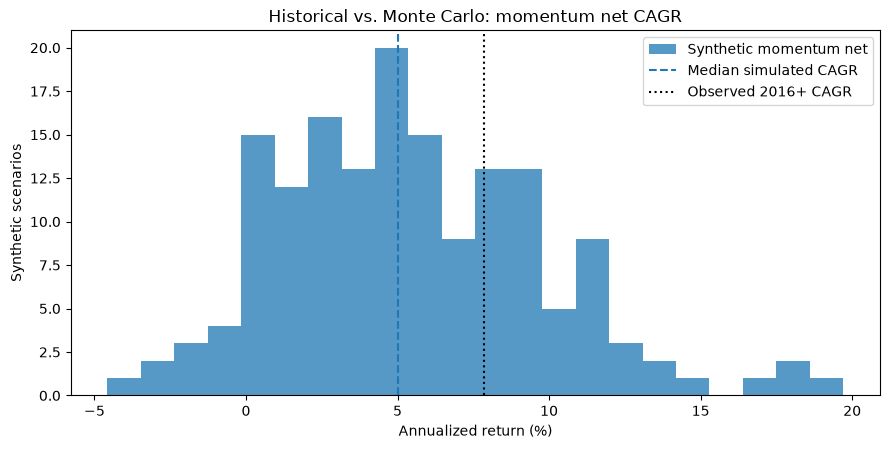

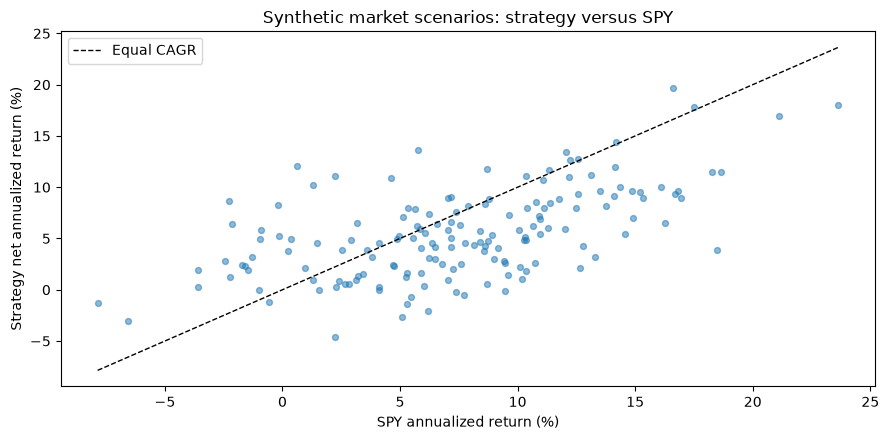

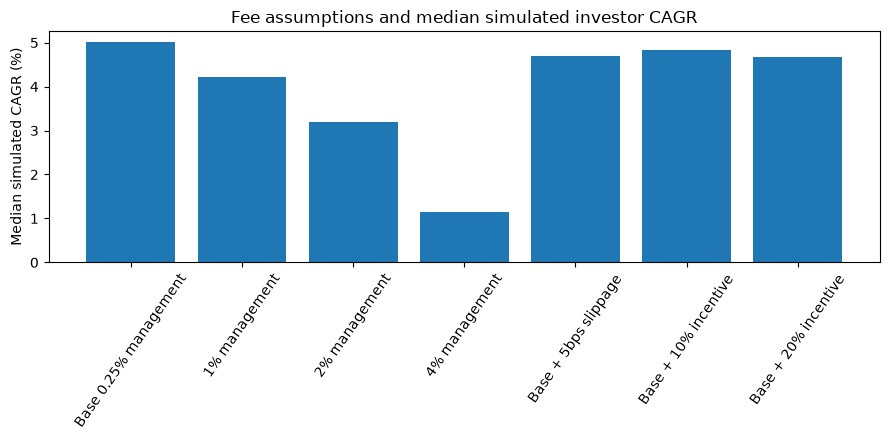

All Checkpoint C checks passed.


In [8]:
fig,ax=plt.subplots(figsize=(9,4.6))
ax.hist(long_results.CAGR*100,bins=22,alpha=.75,label='Synthetic momentum net')
ax.axvline(long_results.CAGR.median()*100,linestyle='--',label='Median simulated CAGR')
ax.axvline(post_stats['CAGR']*100,color='black',linestyle=':',label='Observed 2016+ CAGR')
ax.set(title='Historical vs. Monte Carlo: momentum net CAGR',xlabel='Annualized return (%)',ylabel='Synthetic scenarios')
ax.legend();fig.tight_layout();fig.savefig(FIGURES/'monte_carlo_cagr_distribution.png',dpi=150);plt.show()

fig,ax=plt.subplots(figsize=(9,4.5))
ax.scatter(long_results.SPYCAGR*100,long_results.CAGR*100,alpha=.5,s=18)
lims=[min(long_results.SPYCAGR.min(),long_results.CAGR.min())*100,
      max(long_results.SPYCAGR.max(),long_results.CAGR.max())*100]
ax.plot(lims,lims,linestyle='--',color='black',lw=1,label='Equal CAGR')
ax.set(title='Synthetic market scenarios: strategy versus SPY',
       xlabel='SPY annualized return (%)',ylabel='Strategy net annualized return (%)')
ax.legend();fig.tight_layout();fig.savefig(FIGURES/'monte_carlo_strategy_vs_spy.png',dpi=150);plt.show()

fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar(fee_summary.FeeScenario,fee_summary.MedianCAGR*100)
ax.set(title='Fee assumptions and median simulated investor CAGR',ylabel='Median simulated CAGR (%)')
ax.tick_params(axis='x',labelrotation=55);fig.tight_layout()
fig.savefig(FIGURES/'fee_scenarios.png',dpi=150);plt.show()

# Check simulation results and fee ordering.
assert len(long_results)==N_LONG_PATHS
assert len(wf)==N_WALK_FORWARD_PER_YEAR*10
assert np.isfinite(long_results.select_dtypes(include='number')).all().all()
assert (long_results.EndingWealth>0).all()
assert (long_results.MaxDrawdown<=0).all()
assert all(0<=v<=1 for v in fee_summary.ProbBeatSPY)
assert (hist_signals.TradeDate>hist_signals.SignalDate).all()
assert len(hist_signals)==253
# Higher management fees should not increase final wealth.
pivot=fee_results.pivot(index='Scenario',columns='FeeScenario',values='EndingWealth')
assert (pivot['Base 0.25% management'] >= pivot['1% management']-1e-10).all()
assert (pivot['1% management'] >= pivot['2% management']-1e-10).all()
assert (pivot['2% management'] >= pivot['4% management']-1e-10).all()

manifest={'source':'Yahoo Finance / yfinance archival CSVs from Checkpoint B',
          'archived_download_date':'2026-10-26','analysis_generated_utc':pd.Timestamp.now(tz='UTC').isoformat(),
          'historical_start':str(prices.index.min().date()),'historical_end':str(prices.index.max().date()),
          'rule':'126-day positive momentum and 200-day SMA; top two 50% each; balance SHY',
          'trade_timing':'completed month-end signal / following trading close',
          'mc_calibration_end':'2015-12-31','mc_test_start':'2016-01-04',
          'mc_paths_long_horizon':N_LONG_PATHS,'walk_forward_paths_per_year':N_WALK_FORWARD_PER_YEAR,
          'walk_forward_years':'2016-2025','block_length_mean_days':MEAN_BOOTSTRAP_BLOCK_DAYS,
          'numpy_random_seed':SEED,'baseline_management_fee_annual':BASE_MANAGEMENT_FEE,
          'baseline_trade_cost_bps':BASE_TRADING_BPS,
          'caveat':'Hypothetical stationary-bootstrap paths; not expected returns or real investment results'}
(PROCESSED/'checkpoint_c_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('All Checkpoint C checks passed.')

### 8. Findings and limitations

In the historical backtest, my strategy had lower volatility and smaller drawdowns than SPY, but its CAGR was also lower. The simulated results suggest that performance can change quite a bit across different market paths, especially after higher fees.

The main limitations are the use of adjusted prices instead of actual trading prices, reliance on historical returns to generate simulations, and estimated fees. I would want more independent testing before treating this as a fund that investors could actually use. The machine-learning risk model remains a future step.
